<a href="https://colab.research.google.com/github/AlejandroBlandonV/Analisis-American-Development-Bank/blob/main/S5_ladb_mobility_economy_project_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')


In [ ]:
# mostrar las primeras 5 filas de traffic
traffic.head()

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# mostrar las primeras 5 filas de eco
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [ ]:
# Examinar la estructura de traffic
traffic.info()
traffic.tail(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
1004461,ZAF,pretoria,2024-10-01 10:01:30.000,85.0,21.0,9.7,29.0,16.0,2024-09-24 10:16:30.001,13.690491,13.287302,0.403189
1004462,ZAF,pretoria,2024-10-01 09:01:30.000,68.1,20.0,6.7,23.0,15.0,2024-09-24 09:46:30.000,13.387203,12.983558,0.403646
1004463,ZAF,pretoria,2024-10-01 08:46:30.000,67.7,20.0,6.6,22.0,13.0,2024-09-24 08:46:30.000,13.311492,12.898624,0.412867


En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTC` son de tipo object, es decir, texto. Deben convertirse a date con pd.to_datetime

In [ ]:
# Examinar la estructura de eco
eco.info()
eco.tail(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
27,2024,mexico-city,Mexico,"21.111,00",3.2%,"22,30","22,10"
28,2024,lima,Peru,"13.472,00",6.5%,"19,70","11,20"
29,2024,montevideo,Uruguay,"26.176,00",8.4%,"11,20","1,80"


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, `Population (M)` y `PM2.5 (μg/m³)`  están con formato de texto (object), deben convertirse a float



### 2.2 Renombrar columnas



In [ ]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí
traffic.rename(columns={'City':'city','Country':'country','UpdateTimeUTC':'update_time_utc',
                        'UpdateTimeUTCWeekAgo':'update_time_utc_week_ago','JamsDelay':'jams_delay','TrafficIndexLive':'traffic_index_live',
                        'JamsLengthInKms':'jams_length_kms','JamsCount':'jams_count','TrafficIndexWeekAgo':'traffic_index_week_ago','TravelTimeLivePer10KmsMins':'travel_time_live_per_10kms_mins','TravelTimeHistoricPer10KmsMins':'travel_time_hist_per_10kms_mins','MinsDelay':'mins_delay'}, inplace=True)
# verificar cambios
traffic.columns


Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

In [ ]:
# Estandarizar los nombres de las columnas de eco
#tu código aquí
eco.rename(columns={'City GDP/capita':'city_gdp_capita','Unemployment %':'unemployment_pct','Country':'country','Year':'year','City':'city','Population (M)':'population_m','PM2.5 (μg/m³)':'pm25'}, inplace=True)

# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha



In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors ='coerce', utc=True)
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors ='coerce', utc=True)

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype              
---  ------                           --------------    -----              
 0   country                          1004464 non-null  object             
 1   city                             1004464 non-null  object             
 2   update_time_utc                  1004464 non-null  datetime64[ns, UTC]
 3   jams_delay                       1004464 non-null  float64            
 4   traffic_index_live               1004464 non-null  float64            
 5   jams_length_kms                  1004464 non-null  float64            
 6   jams_count                       1004464 non-null  float64            
 7   traffic_index_week_ago           1004464 non-null  float64            
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns, UTC]
 9   travel_time_live_per_10kms_mins  1004464 non-n

In [ ]:
# Limpia separadores y convierte columnas numéricas en eco


eco['city_gdp_capita'] =(eco['city_gdp_capita'].astype("string").str.strip().str.replace(".", "", regex=False).str.replace(",",".",regex=False))
eco['city_gdp_capita']=pd.to_numeric(eco['city_gdp_capita'],errors='coerce')

eco['unemployment_pct']=(eco['unemployment_pct'].astype("string").str.strip().str.replace(",",".").str.replace("%",""))
eco['unemployment_pct']=pd.to_numeric(eco['unemployment_pct'],errors='coerce')

eco['population_m']=(eco['population_m'].astype("string").str.strip().str.replace(",","."))
eco['population_m']=pd.to_numeric(eco['population_m'],errors='coerce')


# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population_m']*1000000

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0


In [ ]:
#Verificar unicidad de Ciudades Y paises en los datasets
#En Traffic
traffic['country'].unique()

array(['ARE', 'ARG', 'AUS', 'AUT', 'BEL', 'BGR', 'BRA', 'CAN', 'CHE',
       'CHL', 'COL', 'CZE', 'DEU', 'DNK', 'EGY', 'ESP', 'EST', 'FIN',
       'FRA', 'GBR', 'GRC', 'HKG', 'HUN', 'IDN', 'IND', 'IRL', 'ISL',
       'ITA', 'JPN', 'KWT', 'LTU', 'LUX', 'LVA', 'MEX', 'MYS', 'NLD',
       'NOR', 'NZL', 'PER', 'PHL', 'POL', 'PRT', 'QAT', 'ROU', 'SAU',
       'SGP', 'SVK', 'SVN', 'SWE', 'THA', 'TUR', 'TWN', 'URY', 'USA',
       'ZAF'], dtype=object)

In [ ]:
traffic['city'].unique()

array(['abu-dhabi', 'al-ain', 'dubai', 'fujairah', 'ras-al-khaimah',
       'sharja', 'buenos-aires', 'adelaide', 'brisbane', 'canberra',
       'gold-coast', 'hobart', 'melbourne', 'newcastle', 'perth',
       'sydney', 'wollongong', 'graz', 'innsbruck', 'linz', 'salzburg',
       'vienna', 'antwerp', 'bruges', 'brussels', 'charleroi', 'ghent',
       'kortrijk', 'leuven', 'liege', 'mons', 'namur', 'sofia',
       'belo-horizonte', 'brasilia', 'curitiba', 'fortaleza',
       'porto-alegre', 'recife', 'rio-de-janeiro', 'salvador',
       'sao-paulo', 'calgary', 'edmonton', 'halifax', 'hamilton',
       'kitchener-waterloo', 'london', 'montreal', 'ottawa', 'quebec',
       'toronto', 'vancouver', 'winnipeg', 'basel', 'bern', 'geneva',
       'lausanne', 'lugano', 'zurich', 'santiago', 'bogota', 'brno',
       'ostrava', 'prague', 'aachen', 'augsburg', 'berlin', 'bielefeld',
       'bonn', 'bremen', 'cologne', 'dresden', 'dusseldorf',
       'frankfurt-am-main', 'freiburg', 'hamburg', 'h

In [ ]:
# En eco
eco['country'].unique()

array(['Argentina', 'Brazil', 'Chile', 'Colombia', 'Mexico', 'Peru',
       'Uruguay'], dtype=object)

In [ ]:
eco['city'].unique()

array(['buenos-aires', 'sao-paulo', 'rio-de-janeiro', 'brasilia',
       'salvador', 'fortaleza', 'belo-horizonte', 'curitiba', 'recife',
       'porto-alegre', 'santiago', 'bogota', 'mexico-city', 'lima',
       'montevideo'], dtype=object)


---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = pd.to_datetime(traffic['update_time_utc']).dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001000+00:00,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30+00:00,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00+00:00,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001000+00:00,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30+00:00,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30+00:00,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year']==2024].copy()
eco_2024 = eco[eco['year']==2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30+00:00,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001000+00:00,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30+00:00,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30+00:00,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30+00:00,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30+00:00,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001000+00:00,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001000+00:00,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00+00:00,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00+00:00,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).


---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = (
    traffic_2024.groupby(['country', 'city', 'year'])
    .agg({
        'jams_delay': 'mean',
        'traffic_index_live': 'mean',
        'jams_length_kms': 'mean',
        'jams_count': 'mean',
        'mins_delay': 'mean',
        'travel_time_live_per_10kms_mins': 'mean',
        'travel_time_hist_per_10kms_mins': 'mean'
    })
    .reset_index()
)

# Mostrar resultado
traffic_city_year_2024.head()

,country,city,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,ARE,abu-dhabi,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
1,ARE,al-ain,2024,43.119862,11.698618,4.533290,12.623489,0.161476,10.630736,10.469260
2,ARE,dubai,2024,1265.685376,31.214624,189.540172,312.892473,0.848248,12.237314,11.389066
3,ARE,fujairah,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
4,ARE,ras-al-khaimah,2024,9.687467,10.761925,1.152082,3.000867,0.154387,10.789596,10.635209


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [ ]:
# tu código aquí
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,country,city,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
222,MEX,mexico-city,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
217,JPN,tokyo,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
352,USA,new-york,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
163,GBR,london,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
252,PHL,manila,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
247,NZL,dunedin,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
284,SWE,uppsala,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
3,ARE,fujairah,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
224,NLD,almere,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es Ciudad de México con un promedio de retraso de 2833 min


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[(left_cols)].copy()
eco_2024_small = eco_2024[(right_cols)].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small,eco_2024_small, on =['city','year'], how ='inner')

# Mostrar las primeras 5 filas
merged.head()
merged.info()
merged['city'].unique()
merged['country'].unique()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   city                             15 non-null     object 
 1   country                          15 non-null     object 
 2   year                             15 non-null     int64  
 3   jams_delay                       15 non-null     float64
 4   traffic_index_live               15 non-null     float64
 5   jams_length_kms                  15 non-null     float64
 6   jams_count                       15 non-null     float64
 7   mins_delay                       15 non-null     float64
 8   travel_time_live_per_10kms_mins  15 non-null     float64
 9   travel_time_hist_per_10kms_mins  15 non-null     float64
 10  city_gdp_capita                  15 non-null     float64
 11  unemployment_pct                 15 non-null     float64
 12  pm25                    

array(['ARG', 'BRA', 'CHL', 'COL', 'MEX', 'PER', 'URY'], dtype=object)


---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

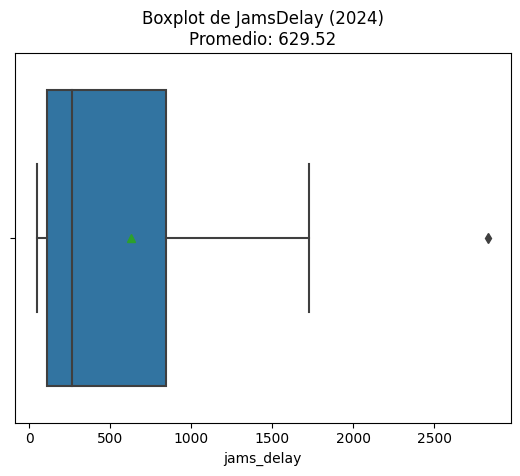

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico
sns.boxplot(data=merged, x='jams_delay',showmeans=True)
# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


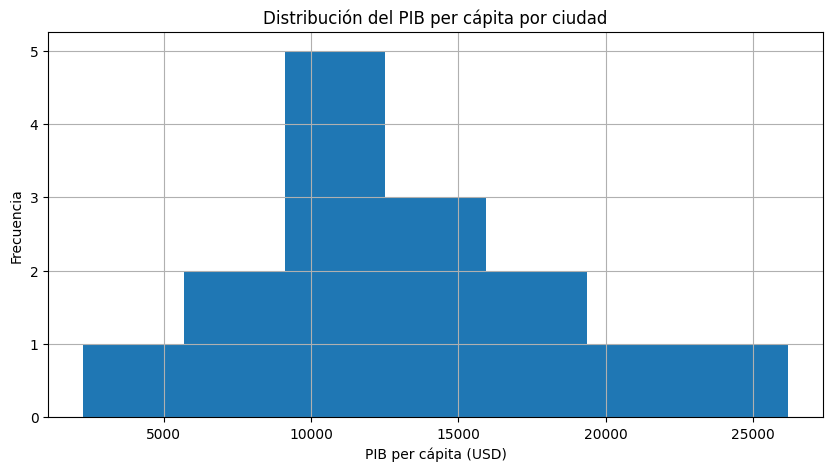

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)

merged['city_gdp_capita'].hist(bins=7,figsize=(10,5))
plt.title('Distribución del PIB per cápita por ciudad')

plt.xlabel('PIB per cápita (USD)')

plt.ylabel('Frecuencia')

plt.show()

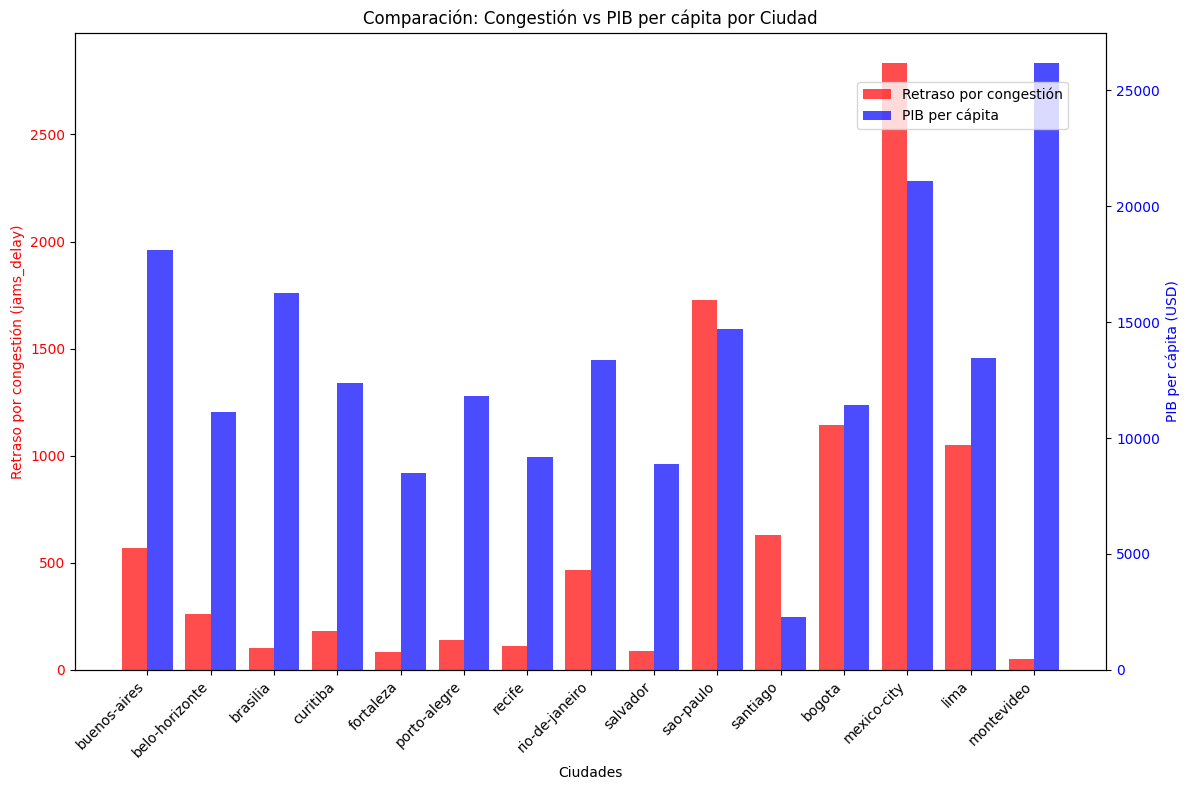

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
#merged.plot( ... , y=['jams_delay', 'city_gdp_capita'])
# Crear figura y primer eje
fig, ax1 = plt.subplots(figsize=(12, 8))

# Configurar el primer eje (jams_delay)
x_pos = range(len(merged))
bars1 = ax1.bar([x - 0.2 for x in x_pos], merged['jams_delay'],
                width=0.4, label='Retraso por congestión',
                color='red', alpha=0.7)

ax1.set_xlabel('Ciudades')
ax1.set_ylabel('Retraso por congestión (jams_delay)', color='red')
ax1.tick_params(axis='y', labelcolor='red')

# Crear segundo eje (city_gdp_capita)
ax2 = ax1.twinx()
bars2 = ax2.bar([x + 0.2 for x in x_pos], merged['city_gdp_capita'],
                width=0.4, label='PIB per cápita',
                color='blue', alpha=0.7)

ax2.set_ylabel('PIB per cápita (USD)', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

# Configurar etiquetas del eje X
ax1.set_xticks(x_pos)
ax1.set_xticklabels(merged['city'], rotation=45, ha='right')

# Título y leyenda
plt.title('Comparación: Congestión vs PIB per cápita por Ciudad')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.9))

plt.tight_layout()
plt.xticks(rotation=90)
plt.show()


In [ ]:
# Calcular correlaciones entre todas las variables numéricas
correlation_matrix = merged.select_dtypes(include=['float64', 'int64']).corr()

# Mostrar la matriz
print(correlation_matrix)

                                 year  jams_delay  traffic_index_live  \
year                              NaN         NaN                 NaN   
jams_delay                        NaN    1.000000            0.765017   
traffic_index_live                NaN    0.765017            1.000000   
jams_length_kms                   NaN    0.992445            0.719139   
jams_count                        NaN    0.994274            0.736544   
mins_delay                        NaN    0.876811            0.892927   
travel_time_live_per_10kms_mins   NaN    0.568016            0.838366   
travel_time_hist_per_10kms_mins   NaN    0.468633            0.780058   
city_gdp_capita                   NaN    0.282975            0.056001   
unemployment_pct                  NaN   -0.686956           -0.293692   
population                        NaN    0.878525            0.647225   

                                 jams_length_kms  jams_count  mins_delay  \
year                                         Na

**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

Escribe tus comentarios:
Observando el gráfico de "Comparación", se claramente que no hay una correlación exacta entre las variables, ya que algunas ciudades con altos retrasos por con gestión tienen un PIB per Capita menor [sao-paulo, mexico-city, santiago] Sin embargo, en el resto de ciudades si se observa una correlación inversa, mientras más grande es el PIB, menores son los retrasos por congestión.


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)


---

# 🧾 Resumen ejecutivo

**Contexto & objetivo:**  
La empresa Latin American Development Bank quiere saber si existe una relación entre la movilidad urbana y la productividad económica de las principales ciudades de Latinoamérica.
Para el análisis se trabajan dos bases de datos:
1.Movilidad urbana: TomTom Traffic Index (datos de tráfico en tiempo real).
2.Economía urbana: OECD Cities (PIB per cápita, desempleo y población).

**Cobertura de datos:**  
- Año analizado 2024
- Ciudades analizadas 'buenos-aires', 'belo-horizonte', 'brasilia', 'curitiba',
       'fortaleza', 'porto-alegre', 'recife', 'rio-de-janeiro',
       'salvador', 'sao-paulo', 'santiago', 'bogota', 'mexico-city',
       'lima', 'montevideo'
-Países Analizados 'ARGENTINA', 'BRASIL', 'CHILE', 'COLOMBIA', 'MEXICO', 'PERU', 'URUGUAY

**Metodología (alto nivel):**  
- Se verificaron los tipos de datos de ambos datasets para realizar respectivos cambios a aquellas columnas que no correspondieran a su naturalidad.
- Para el DataFrame de traffic: se convirtieron las columnas correspondientes de **object** a **datetime**

traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors ='coerce', utc=True)

traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors ='coerce', utc=True).

- Para el DataFrame eco: se estandarizaron y limpiaron las siguientes columnas
- eco['city_gdp_capita'] =(eco['city_gdp_capita'].astype("string").str.strip().str.replace(".", "", regex=False).str.replace(",",".",regex=False))
eco['city_gdp_capita']=pd.to_numeric(eco['city_gdp_capita'],errors='coerce')

eco['unemployment_pct']=(eco['unemployment_pct'].astype("string").str.strip().str.replace(",",".").str.replace("%",""))
eco['unemployment_pct']=pd.to_numeric(eco['unemployment_pct'],errors='coerce')

eco['population_m']=(eco['population_m'].astype("string").str.strip().str.replace(",","."))
eco['population_m']=pd.to_numeric(eco['population_m'],errors='coerce')

- Se tomó la decisión de hacer un merge con "inner", para traer las coincidencias exactas de ambos DataFrames cuyas llaves fueron las columnas ['city'] y ['year'] con el fin de agruparlos y tener un Dataset resumido por año (2024) y por ciudades.
  
- Se empleó un Boxplot de la columna ['jams_delay'] para detectar la media, la mediana y valores atípicos.
- Se emmpleó un Histograma para verificar el tipo de distribución de los datos de la columna ['city_gdp_capita']

**Hallazgos iniciales:**  
 Observando el gráfico de "Comparación", se claramente que no hay una correlación exacta entre las variables, ya que algunas ciudades con altos retrasos por con gestión tienen un PIB per Capita menor [sao-paulo, mexico-city, santiago] Sin embargo, en el resto de ciudades si se observa una correlación inversa, mientras más grande es el PIB, menores son los retrasos por congestión.

- Realizando un análisis profundo, y considerando que las escalas de medición de ambas variables son distintas, se puede inferir que Santiago de chile es la ciudad que su relación de alta congestión vs un bajo PIB es la que más va acorde a la pregunta de negocio. No obstante se observa que Ciudad de México tienes los niveles más altos de congestión, aun teniendo el segundo mejor PIB de las ciudades.

- La ciudad de montevideo debe analizarse más a profundidad, ya que se ven valores mínimos en los retrasos y valores máximos en el PIB

**Recomendaciones**  

Validar fuentes ya que posiblemente halla errores en toma de datos, considerando la ciudad de montevideo, con el mejor PIB y mínimo nivel de congestión.

Teniendo en cuenta la anterior recomendación, si no hubo errores en los datos, estudiar a profundidad el comportamiento de esta ciudad, ¿Hay buena planificación urbana? ¿existe una cultura peatonal y de transporte que evita los trancones y retenes?

En ciudad de México se presenta el mayor nivel de congestión de las 15 ciudades analizadas, pero tiene el mejor segundo PIB. Emplear planes de acción de movilización, invertir en mejoramiento de vías, señalización y cultura, todo esto considerando que es una gran ciudad y tiene un PIB excelente.

Finalemnte para Sao Paulo y Santiago de Chile, ciudades con correlación inversa, alto congestoinamiento y PIB bajo. Realizar campañas de movilización vial para los habitantes. Todo comienza a partir de una buena cultura.
